# MBTI Personality Dataset — EDA

Explore the Kaggle [MBTI Type](https://www.kaggle.com/datasets/datasnaek/mbti-type) dataset before training.

Place `mbti_1.csv` in `notebook/data/` first.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = os.path.join("data", "mbti_1.csv")
df = pd.read_csv(DATA_PATH)
df.head()

,type,posts
0,INFJ,'http://www.youtube.com/watch?v=qsXHcwe3krw|||...
1,ENTP,'I'm finding the lack of me in these posts ver...
2,INTP,'Good one _____ https://www.youtube.com/wat...
3,INTJ,"'Dear INTP, I enjoyed our conversation the o..."
4,ENTJ,'You're fired.|||That's another silly misconce...


In [2]:
df.info()
print("\nShape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nUnique types:", df["type"].nunique())
df["type"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 8675 entries, 0 to 8674
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   type    8675 non-null   str  
 1   posts   8675 non-null   str  
dtypes: str(2)
memory usage: 135.7 KB

Shape: (8675, 2)

Missing values:
 type     0
posts    0
dtype: int64

Unique types: 16


type
INFP    1832
INFJ    1470
INTP    1304
INTJ    1091
ENTP     685
ENFP     675
ISTP     337
ISFP     271
ENTJ     231
ISTJ     205
ENFJ     190
ISFJ     166
ESTP      89
ESFP      48
ESFJ      42
ESTJ      39
Name: count, dtype: int64

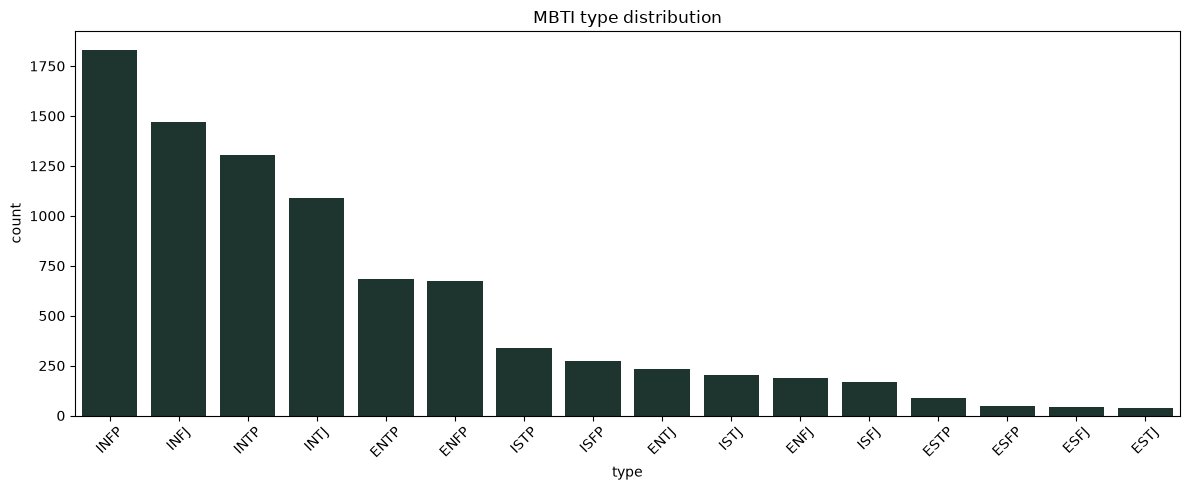

In [3]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="type", order=df["type"].value_counts().index, color="#1a3830")
plt.title("MBTI type distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
df["post_length"] = df["posts"].astype(str).str.len()
df["word_count"] = df["posts"].astype(str).str.split().str.len()
df[["post_length", "word_count"]].describe()

,post_length,word_count
count,8675.000000,8675.000000
mean,7234.989625,1226.241499
std,1607.806938,311.210544
min,57.000000,4.000000
25%,6325.000000,1046.500000
50%,7515.000000,1278.000000
75%,8429.000000,1457.000000
max,10090.000000,1881.000000


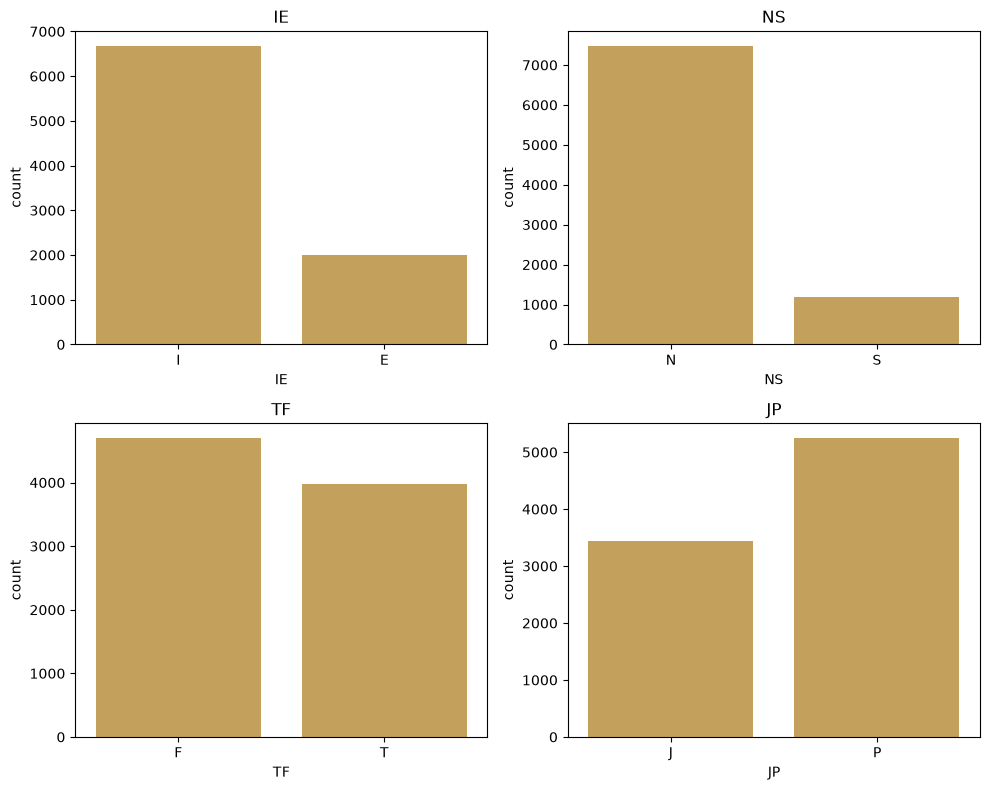

In [5]:
# Split into MBTI dimensions (I/E, N/S, T/F, J/P)
df["IE"] = df["type"].str[0]
df["NS"] = df["type"].str[1]
df["TF"] = df["type"].str[2]
df["JP"] = df["type"].str[3]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.ravel(), ["IE", "NS", "TF", "JP"]):
    sns.countplot(data=df, x=col, ax=ax, color="#d4a54a")
    ax.set_title(col)
plt.tight_layout()
plt.show()